In [ ]:
#pandas import

#Loading Dataframe (csv, excel, dictionary)
#1--df=pd.read_csv("data.csv")
#2--df=pd.read_excel("data.xlsx")
#3--df=pd.DataFrame (data_dict)

#data frame (table) vs series (list)

#view data frame header only

import pandas as pd

# creating a data frame (table) from a dictionary
#by default when a data frame is created every row is given a index

data = {
    "Name": ["John", "Jane", "Bob"],
    "Age": [25, 30, 35],
    "City": ["New York", "London", "Paris"],
    "calories": [420, 380, 390],
    "duration": [50, 40, 45]
}

df = pd.DataFrame(data)
print(df)

# This line was causing a FileNotFoundError. The DataFrame `df` is already created above.
# df = pd.read_csv("/content/orders.csv")


#export data frame to csv, excel, JSON, paquert

df.to_csv("data.csv")
df.to_excel("data.xlsx")

   Name  Age      City  calories  duration
0  John   25  New York       420        50
1  Jane   30    London       380        40
2   Bob   35     Paris       390        45


In [ ]:
#Create Automated EDA Report (Exploratory Data Analysis)

#basic info, head & tail, missing value, duplicates, summary stat, cat.analysis,
#numerical analysis, corr, outliers, unique values, data cleansing suggestions

import pandas as pd
import numpy as np

# creating a data frame (table) from a dictionary
#by default when a data frame is created every row is given a index

data = {
    "Name": ["John", "Jane", "Bob"],
    "Age": [25, 30, 35],
    "City": ["New York", "London", "Paris"],
    "calories": [420, 380, 390],
    "duration": [50, 40, 45]
}

df = pd.DataFrame(data)
print(df)

def EDA_Report(df):
  report={}
  #basic info
  report["Shape"]=df.shape
  report["Dtypes"]=df.dtypes.tolist()
  report["Columns"]=df.columns.tolist()

  #head & tail

  report["Head"]=df.head().to_dict(orient='records')
  report["Tail"]=df.tail().to_dict(orient='records')

  #summary stat
  report["Missing Values"]=df.isnull().sum().to_dict()
  #OR
  report["Has_Missing"]=df.isnull().sum().to_dict()
  report["Duplicates"]=df.duplicated().sum()

  #summary statistics
  report["Summary Statistics"]=df.describe().to_dict()


  #cat.analysis
  report["Categorical Analysis"]={}

  for col in df.select_dtypes(include=object).columns:
    report["Categorical Analysis"][col]=df[col].value_counts().to_dict()

  #numerical analysis
  report["Numerical Analysis"]={}
  for col in df.select_dtypes(include=np.number).columns:
    report["Numerical Analysis"][col]={
        "mean":df[col].mean(),
        "median":df[col].median(),
        "25th":df[col].quantile(0.25),
        "75th":df[col].quantile(0.75),
        "std":df[col].std(),
        "min":df[col].min(),
        "max":df[col].max()
    }

  #correlation
  report["Correlation"]=df.select_dtypes(include=np.number).corr().to_dict()
  return report

eda_results = EDA_Report(df)
display(eda_results)

   Name  Age      City  calories  duration
0  John   25  New York       420        50
1  Jane   30    London       380        40
2   Bob   35     Paris       390        45


{'Shape': (3, 5),
 'Dtypes': [dtype('O'),
  dtype('int64'),
  dtype('O'),
  dtype('int64'),
  dtype('int64')],
 'Columns': ['Name', 'Age', 'City', 'calories', 'duration'],
 'Head': [{'Name': 'John',
   'Age': 25,
   'City': 'New York',
   'calories': 420,
   'duration': 50},
  {'Name': 'Jane',
   'Age': 30,
   'City': 'London',
   'calories': 380,
   'duration': 40},
  {'Name': 'Bob',
   'Age': 35,
   'City': 'Paris',
   'calories': 390,
   'duration': 45}],
 'Tail': [{'Name': 'John',
   'Age': 25,
   'City': 'New York',
   'calories': 420,
   'duration': 50},
  {'Name': 'Jane',
   'Age': 30,
   'City': 'London',
   'calories': 380,
   'duration': 40},
  {'Name': 'Bob',
   'Age': 35,
   'City': 'Paris',
   'calories': 390,
   'duration': 45}],
 'Missing Values': {'Name': 0,
  'Age': 0,
  'City': 0,
  'calories': 0,
  'duration': 0},
 'Has_Missing': {'Name': 0, 'Age': 0, 'City': 0, 'calories': 0, 'duration': 0},
 'Duplicates': np.int64(0),
 'Summary Statistics': {'Age': {'count': 3.0,
 

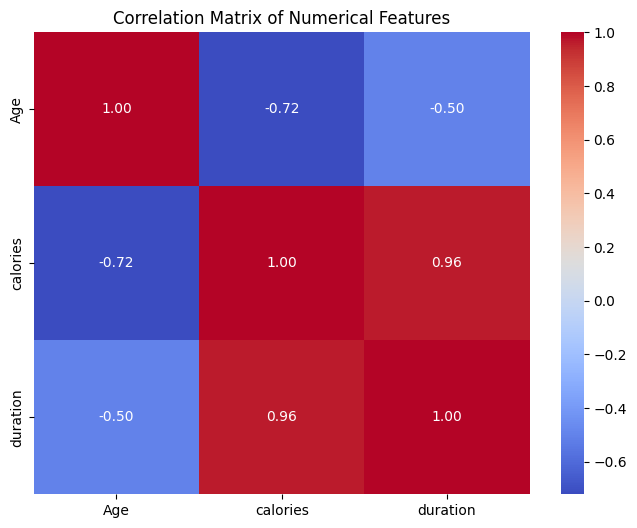

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for correlation calculation
df_numerical = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation_matrix = df_numerical.corr()

# Create a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Features')
plt.show()